# Análisis de Estacionalidad, Demanda y Factores Climáticos en un Negocio de Postres

## Problema de negocio
La empresa presenta variaciones estacionales en sus ventas a lo largo del año. El objetivo del análisis es identificar en qué periodos se concentran las mayores caídas, qué factores podrían estar asociados a estas variaciones y qué acciones comerciales u operativas podrían ayudar a reducir su impacto.

## Pregunta principal de análisis
¿Qué factores están asociados a la disminución de ventas durante los meses de menor demanda y qué estrategias podrían ayudar a estabilizar los ingresos a lo largo del año?

## Hipótesis de análisis
Las ventas podrían verse afectadas por factores como la temperatura, las precipitaciones, la temporada del año, cambios en la demanda por categoría de producto y canal de venta.

## Objetivo del proyecto
Analizar la evolución de las ventas en el tiempo, identificar patrones estacionales y evaluar posibles relaciones entre las condiciones climáticas y el comportamiento de compra, con el fin de proponer acciones basadas en datos.


## Preparación de los datos

Para este análisis se utilizará un conjunto de datos con mayor nivel de detalle que permita evaluar no solo la evolución mensual de las ventas, sino también posibles factores asociados a la demanda.

Las variables principales consideradas para el análisis serán:

- Fecha
- Sucursal
- Producto
- Categoría
- Unidades vendidas
- Ingreso por venta
- Número de clientes
- Canal de venta
- Promociones o descuentos
- Temperatura
- Precipitaciones
- Temporada del año

El objetivo de esta etapa es disponer de información suficientemente detallada para analizar patrones de estacionalidad, comportamiento de compra y posibles relaciones entre las condiciones climáticas y las ventas.

**Nota sobre los datos:**  
El dataset utilizado en este proyecto es sintético y fue generado con fines de análisis. Su estructura simula el comportamiento de un negocio de postres con sucursales en Santiago de Chile e incorpora variables comerciales y climáticas diseñadas para representar escenarios de negocio realistas. Los valores monetarios están expresados en pesos chilenos (CLP).

In [ ]:
import pandas as pd
import numpy as np

# Para que los datos generados sean reproducibles
np.random.seed(42)

# Fechas: 2 años completos
fechas = pd.date_range(
    start="2024-01-01",
    end="2025-12-31",
    freq="D"
)

sucursales = ["Ñuñoa", "Providencia", "Las Condes"]

productos = {
    "Helado Thai": ("Postres fríos", 5500),
    "Açaí Bowl": ("Postres fríos", 6500),
    "Yogurt Griego": ("Postres fríos", 5900),
    "Waffle": ("Postres calientes", 5200),
    "Brownie": ("Postres calientes", 3900),
    "Galleta NY": ("Postres calientes", 3200),
    "Café": ("Bebidas calientes", 3000),
    "Chocolate Caliente": ("Bebidas calientes", 3500),
}

canales = ["Tienda", "Delivery"]

filas = []

for fecha in fechas:

    mes = fecha.month
    dia_semana = fecha.dayofweek

    # Temporadas de Chile
    if mes in [12, 1, 2]:
        temporada = "Verano"
        temperatura = np.random.normal(25, 3)
        prob_lluvia = 0.05

    elif mes in [3, 4, 5]:
        temporada = "Otoño"
        temperatura = np.random.normal(17, 3)
        prob_lluvia = 0.20

    elif mes in [6, 7, 8]:
        temporada = "Invierno"
        temperatura = np.random.normal(10, 3)
        prob_lluvia = 0.35

    else:
        temporada = "Primavera"
        temperatura = np.random.normal(19, 3)
        prob_lluvia = 0.15

    precipitacion = (
        np.random.uniform(2, 25)
        if np.random.random() < prob_lluvia
        else 0
    )

    for sucursal in sucursales:

        factor_sucursal = {
            "Ñuñoa": 1.00,
            "Providencia": 1.15,
            "Las Condes": 1.10
        }[sucursal]

        for producto, (categoria, precio_base) in productos.items():

            for canal in canales:

                # Demanda base
                demanda = 8 * factor_sucursal

                # Fin de semana
                if dia_semana >= 5:
                    demanda *= 1.30

                # Efecto del clima según tipo de producto
                if categoria == "Postres fríos":
                    demanda *= max(0.40, temperatura / 20)

                elif categoria == "Bebidas calientes":
                    demanda *= max(0.50, 20 / max(temperatura, 5))

                # La lluvia reduce tienda pero aumenta delivery
                if precipitacion > 0:
                    if canal == "Tienda":
                        demanda *= 0.65
                    else:
                        demanda *= 1.35

                # Promoción aleatoria
                promocion = np.random.random() < 0.12
                descuento = 0.10 if promocion else 0

                if promocion:
                    demanda *= 1.20

                # Delivery representa menos volumen normalmente
                if canal == "Delivery":
                    demanda *= 0.65

                unidades = max(
                    0,
                    int(np.random.normal(demanda, 2))
                )

                precio = round(
                    precio_base * np.random.uniform(0.97, 1.03),
                    0
                )

                ingreso = unidades * precio * (1 - descuento)

                clientes = max(
                    1,
                    int(unidades / np.random.uniform(1.1, 1.8))
                ) if unidades > 0 else 0

                filas.append({
                    "fecha": fecha,
                    "sucursal": sucursal,
                    "producto": producto,
                    "categoria": categoria,
                    "canal": canal,
                    "unidades": unidades,
                    "precio": precio,
                    "descuento": descuento,
                    "ingreso": round(ingreso, 0),
                    "clientes": clientes,
                    "temperatura": round(temperatura, 1),
                    "precipitacion_mm": round(precipitacion, 1),
                    "temporada": temporada
                })

df = pd.DataFrame(filas)

# Guardamos una copia por si la necesitamos después
df.to_csv(
    "/content/datos_postres_santiago.csv",
    index=False
)

print("Cantidad de filas:", len(df))
print("Cantidad de columnas:", len(df.columns))

df.head()

Cantidad de filas: 35088
Cantidad de columnas: 13


,fecha,sucursal,producto,categoria,canal,unidades,precio,descuento,ingreso,clientes,temperatura,precipitacion_mm,temporada
0,2024-01-01,Ñuñoa,Helado Thai,Postres fríos,Tienda,10,5386.0,0.0,53860.0,8,26.5,0.0,Verano
1,2024-01-01,Ñuñoa,Helado Thai,Postres fríos,Delivery,8,5569.0,0.1,40097.0,7,26.5,0.0,Verano
2,2024-01-01,Ñuñoa,Açaí Bowl,Postres fríos,Tienda,12,6630.0,0.0,79560.0,9,26.5,0.0,Verano
3,2024-01-01,Ñuñoa,Açaí Bowl,Postres fríos,Delivery,5,6510.0,0.0,32550.0,3,26.5,0.0,Verano
4,2024-01-01,Ñuñoa,Yogurt Griego,Postres fríos,Tienda,8,5940.0,0.0,47520.0,6,26.5,0.0,Verano


## Exploración inicial y calidad de los datos

Antes de comenzar el análisis, se revisará la estructura general del dataset para validar la calidad de la información.

En esta etapa se analizarán:

- Dimensiones del dataset.
- Tipos de datos.
- Valores nulos.
- Registros duplicados.
- Estadísticas descriptivas básicas.
- Rango de fechas disponible.

Esta revisión permitirá detectar posibles problemas de calidad antes de avanzar al análisis de ventas y estacionalidad.

In [ ]:
# Dimensiones del dataset
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\n--- TIPOS DE DATOS ---")
print(df.dtypes)

print("\n--- VALORES NULOS ---")
print(df.isnull().sum())

print("\n--- REGISTROS DUPLICADOS ---")
print("Duplicados:", df.duplicated().sum())

print("\n--- RANGO DE FECHAS ---")
print("Fecha mínima:", df["fecha"].min())
print("Fecha máxima:", df["fecha"].max())

print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

Filas: 35088
Columnas: 13

--- TIPOS DE DATOS ---
fecha               datetime64[ns]
sucursal                    object
producto                    object
categoria                   object
canal                       object
unidades                     int64
precio                     float64
descuento                  float64
ingreso                    float64
clientes                     int64
temperatura                float64
precipitacion_mm           float64
temporada                   object
dtype: object

--- VALORES NULOS ---
fecha               0
sucursal            0
producto            0
categoria           0
canal               0
unidades            0
precio              0
descuento           0
ingreso             0
clientes            0
temperatura         0
precipitacion_mm    0
temporada           0
dtype: int64

--- REGISTROS DUPLICADOS ---
Duplicados: 0

--- RANGO DE FECHAS ---
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2025-12-31 00:00:00

--- ESTADÍSTICAS DESC

,fecha,unidades,precio,descuento,ingreso,clientes,temperatura,precipitacion_mm
count,35088,"35,088","35,088","35,088","35,088","35,088","35,088","35,088"
mean,2024-12-30 23:59:59.999999744,8,"4,588",0,"33,332",5,18,2
min,2024-01-01 00:00:00,0,"2,910",0,0,0,1,0
25%,2024-07-01 00:00:00,5,"3,370",0,"20,716",3,13,0
50%,2024-12-31 00:00:00,7,"4,530",0,"30,544",4,18,0
75%,2025-07-02 00:00:00,10,"5,680",0,"42,610",6,22,0
max,2025-12-31 00:00:00,54,"6,695",0,"172,579",39,34,25
std,NaN,4,"1,262",0,"18,299",3,6,6


## Preparación de variables para el análisis

A partir de la variable fecha se crearán campos adicionales que facilitarán el análisis temporal y la comparación del comportamiento de ventas.

Se incorporarán variables como:

- Año
- Número de mes
- Nombre del mes
- Día de la semana
- Indicador de fin de semana

Estas variables permitirán analizar patrones mensuales, diferencias entre días hábiles y fines de semana y comparar el comportamiento entre años.

In [ ]:
# Crear variables temporales
df["anio"] = df["fecha"].dt.year
df["mes_numero"] = df["fecha"].dt.month

meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

df["mes"] = df["fecha"].dt.month.map(meses)
df["dia_semana"] = df["fecha"].dt.dayofweek.map(dias)
df["fin_de_semana"] = df["fecha"].dt.dayofweek >= 5

# Revisar las nuevas columnas
df[
    ["fecha", "anio", "mes_numero", "mes", "dia_semana", "fin_de_semana"]
].head()

,fecha,anio,mes_numero,mes,dia_semana,fin_de_semana
0,2024-01-01,2024,1,Enero,Lunes,False
1,2024-01-01,2024,1,Enero,Lunes,False
2,2024-01-01,2024,1,Enero,Lunes,False
3,2024-01-01,2024,1,Enero,Lunes,False
4,2024-01-01,2024,1,Enero,Lunes,False


## Análisis temporal de las ventas

En esta etapa se analizará cómo evolucionan las ventas a lo largo del tiempo para identificar patrones estacionales y diferencias entre meses, años y temporadas.

Se evaluarán:

- Ingresos mensuales.
- Unidades vendidas por mes.
- Comparación entre 2024 y 2025.
- Comportamiento por temporada.
- Meses con mayor y menor demanda.

In [ ]:
# Resumen mensual de ventas
ventas_mensuales = (
    df.groupby(["anio", "mes_numero", "mes"])
      .agg(
          ingreso_total=("ingreso", "sum"),
          unidades_totales=("unidades", "sum"),
          clientes_totales=("clientes", "sum")
      )
      .reset_index()
      .sort_values(["anio", "mes_numero"])
)

ventas_mensuales.head(12)

,anio,mes_numero,mes,ingreso_total,unidades_totales,clientes_totales
0,2024,1,Enero,"54,525,453",11568,7428
1,2024,2,Febrero,"50,333,585",10693,6822
2,2024,3,Marzo,"48,008,073",11012,7035
3,2024,4,Abril,"45,742,373",10497,6702
4,2024,5,Mayo,"47,079,949",10892,6927
5,2024,6,Junio,"46,998,091",12000,7772
6,2024,7,Julio,"46,623,924",11704,7615
7,2024,8,Agosto,"47,238,902",12067,7848
8,2024,9,Septiembre,"47,560,403",10583,6743
9,2024,10,Octubre,"48,446,709",10864,6924


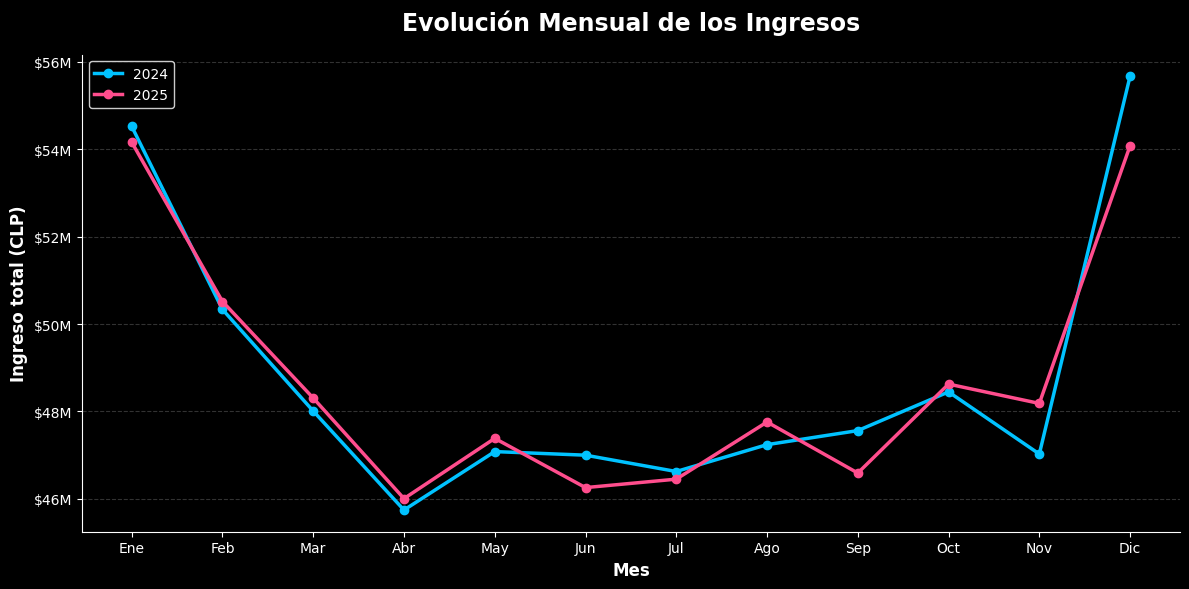

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Preparar los datos
ventas_grafico = ventas_mensuales.pivot(
    index="mes_numero",
    columns="anio",
    values="ingreso_total"
)

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 6), facecolor="black")
ax.set_facecolor("black")

# Líneas por año
ax.plot(
    ventas_grafico.index,
    ventas_grafico[2024],
    marker="o",
    linewidth=2.5,
    label="2024",
    color="#00C2FF"
)

ax.plot(
    ventas_grafico.index,
    ventas_grafico[2025],
    marker="o",
    linewidth=2.5,
    label="2025",
    color="#FF4D8D"
)

# Título y ejes
ax.set_title(
    "Evolución Mensual de los Ingresos",
    fontsize=17,
    fontweight="bold",
    color="white",
    pad=18
)

ax.set_xlabel(
    "Mes",
    fontsize=12,
    fontweight="bold",
    color="white"
)

ax.set_ylabel(
    "Ingreso total (CLP)",
    fontsize=12,
    fontweight="bold",
    color="white"
)

# Meses en eje X
ax.set_xticks(range(1, 13))
ax.set_xticklabels(
    nombres_meses,
    color="white"
)

# Mostrar eje Y en millones
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1_000_000:.0f}M")
)

ax.tick_params(axis="y", colors="white")

# Cuadrícula suave
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

# Bordes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

# Leyenda
legend = ax.legend(
    facecolor="black",
    edgecolor="white"
)

for texto in legend.get_texts():
    texto.set_color("white")

plt.tight_layout()
plt.show()

### Hallazgo

Los ingresos presentan variaciones a lo largo del año y muestran un patrón similar entre 2024 y 2025. Sin embargo, la evolución mensual por sí sola no permite determinar qué categorías explican estos cambios, por lo que el análisis se profundiza posteriormente por temporada, categoría y condiciones climáticas.

## Análisis por temporada y categoría

Para comprender mejor la estacionalidad, se analizará cómo cambia la demanda de cada categoría de producto según la temporada del año.

Esto permitirá identificar si las variaciones en ventas se deben a una disminución general de la demanda o a cambios en las preferencias de consumo entre categorías.

In [ ]:
temporada_categoria = (
    df.groupby(["temporada", "categoria"])
      .agg(
          ingreso_total=("ingreso", "sum"),
          unidades_totales=("unidades", "sum")
      )
      .reset_index()
)

temporada_categoria

,temporada,categoria,ingreso_total,unidades_totales
0,Invierno,Bebidas calientes,"110,449,569",34516
1,Invierno,Postres calientes,"97,342,612",24130
2,Invierno,Postres fríos,"73,530,449",12514
3,Otoño,Bebidas calientes,"65,056,110",20274
4,Otoño,Postres calientes,"97,983,508",24214
5,Otoño,Postres fríos,"119,483,504",20337
6,Primavera,Bebidas calientes,"56,947,492",17769
7,Primavera,Postres calientes,"97,569,561",24111
8,Primavera,Postres fríos,"131,910,992",22425
9,Verano,Bebidas calientes,"41,071,629",12820


## Relación entre temperatura y demanda

Para profundizar el análisis estacional, se evaluará cómo cambia la demanda de las principales categorías según la temperatura.

El objetivo es identificar si existe una relación entre las condiciones térmicas y el comportamiento de compra, especialmente en productos fríos y bebidas calientes.

In [ ]:
# Crear rangos de temperatura
df["rango_temperatura"] = pd.cut(
    df["temperatura"],
    bins=[-10, 10, 15, 20, 25, 40],
    labels=[
        "Muy baja",
        "Baja",
        "Templada",
        "Cálida",
        "Muy cálida"
    ]
)

temperatura_categoria = (
    df.groupby(
        ["rango_temperatura", "categoria"],
        observed=False
    )
    .agg(
        ingreso_total=("ingreso", "sum"),
        unidades_totales=("unidades", "sum")
    )
    .reset_index()
)

temperatura_categoria

,rango_temperatura,categoria,ingreso_total,unidades_totales
0,Muy baja,Bebidas calientes,"67,817,619",21192
1,Muy baja,Postres calientes,"46,727,387",11604
2,Muy baja,Postres fríos,"27,598,628",4697
3,Baja,Bebidas calientes,"68,199,905",21301
4,Baja,Postres calientes,"79,472,755",19674
5,Baja,Postres fríos,"70,961,263",12080
6,Templada,Bebidas calientes,"75,509,492",23531
7,Templada,Postres calientes,"123,292,594",30465
8,Templada,Postres fríos,"155,129,224",26385
9,Cálida,Bebidas calientes,"40,870,963",12764


## Demanda promedio según temperatura

Los totales acumulados pueden verse afectados por la cantidad de días que pertenecen a cada rango de temperatura. Por esta razón, se analizará la demanda promedio para comparar el comportamiento de las categorías en condiciones térmicas distintas de manera más justa.

In [ ]:
# Ventas diarias por categoría y rango de temperatura
ventas_diarias_temp = (
    df.groupby(
        ["fecha", "rango_temperatura", "categoria"],
        observed=True
    )
    .agg(
        unidades_diarias=("unidades", "sum"),
        ingreso_diario=("ingreso", "sum")
    )
    .reset_index()
)

# Promedio diario por rango de temperatura y categoría
promedio_temp_categoria = (
    ventas_diarias_temp.groupby(
        ["rango_temperatura", "categoria"],
        observed=True
    )
    .agg(
        promedio_unidades_dia=("unidades_diarias", "mean"),
        promedio_ingreso_dia=("ingreso_diario", "mean")
    )
    .reset_index()
)

promedio_temp_categoria

,rango_temperatura,categoria,promedio_unidades_dia,promedio_ingreso_dia
0,Muy baja,Bebidas calientes,241,"770,655"
1,Muy baja,Postres calientes,132,"530,993"
2,Muy baja,Postres fríos,53,"313,621"
3,Baja,Bebidas calientes,141,"451,655"
4,Baja,Postres calientes,130,"526,310"
5,Baja,Postres fríos,80,"469,942"
6,Templada,Bebidas calientes,102,"326,881"
7,Templada,Postres calientes,132,"533,734"
8,Templada,Postres fríos,114,"671,555"
9,Cálida,Bebidas calientes,81,"258,677"


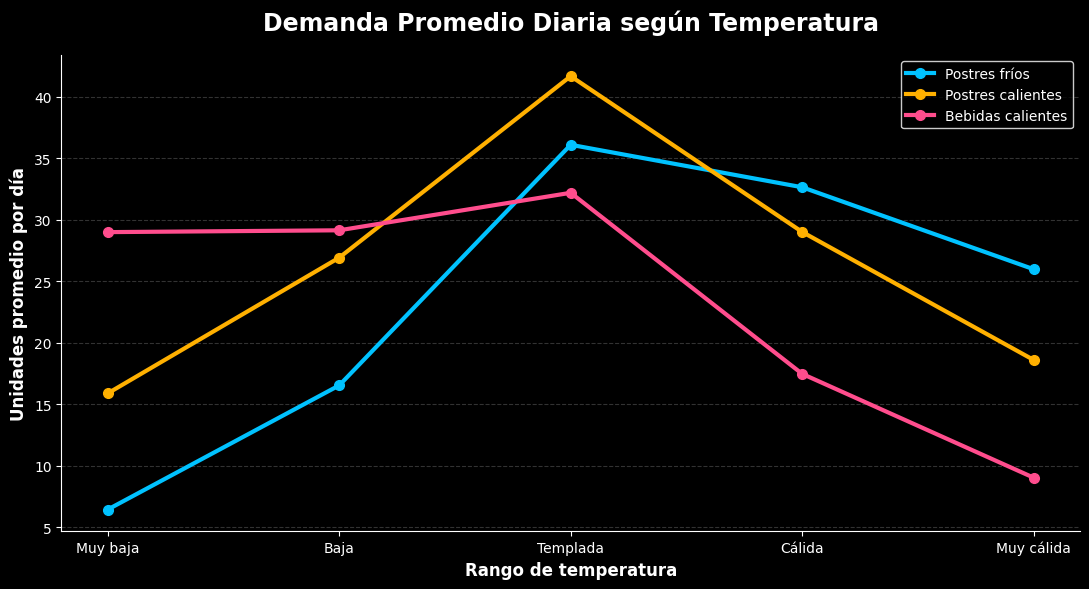

In [ ]:
# Preparar datos para el gráfico
orden_temperatura = [
    "Muy baja",
    "Baja",
    "Templada",
    "Cálida",
    "Muy cálida"
]

grafico_temp = promedio_temp_categoria.pivot(
    index="rango_temperatura",
    columns="categoria",
    values="promedio_unidades_dia"
)

grafico_temp = grafico_temp.reindex(orden_temperatura)

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 6), facecolor="black")
ax.set_facecolor("black")

# Líneas por categoría
ax.plot(
    grafico_temp.index,
    grafico_temp["Postres fríos"],
    marker="o",
    linewidth=3,
    markersize=7,
    label="Postres fríos",
    color="#00C2FF"
)

ax.plot(
    grafico_temp.index,
    grafico_temp["Postres calientes"],
    marker="o",
    linewidth=3,
    markersize=7,
    label="Postres calientes",
    color="#FFB000"
)

ax.plot(
    grafico_temp.index,
    grafico_temp["Bebidas calientes"],
    marker="o",
    linewidth=3,
    markersize=7,
    label="Bebidas calientes",
    color="#FF4D8D"
)

# Título
ax.set_title(
    "Demanda Promedio Diaria según Temperatura",
    fontsize=17,
    fontweight="bold",
    color="white",
    pad=18
)

# Ejes
ax.set_xlabel(
    "Rango de temperatura",
    fontsize=12,
    fontweight="bold",
    color="white"
)

ax.set_ylabel(
    "Unidades promedio por día",
    fontsize=12,
    fontweight="bold",
    color="white"
)

# Estilo
ax.tick_params(axis="x", colors="white")
ax.tick_params(axis="y", colors="white")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

# Leyenda
legend = ax.legend(
    facecolor="black",
    edgecolor="white"
)

for texto in legend.get_texts():
    texto.set_color("white")

plt.tight_layout()
plt.show()

### Hallazgo

La temperatura muestra una relación clara con el comportamiento de compra dentro del escenario analizado.

- En temperaturas bajas aumenta la demanda promedio de bebidas calientes.
- Los postres fríos presentan su menor demanda en temperaturas muy bajas y aumentan a medida que sube la temperatura.
- Los postres calientes muestran un comportamiento más estable entre distintos rangos térmicos.

Estos resultados sugieren que la estacionalidad no afecta por igual a todas las categorías, sino que modifica la composición de la demanda.

## Impacto de las precipitaciones en el canal de venta

Se analizará si las precipitaciones modifican el comportamiento de compra entre tienda física y delivery.

El objetivo es identificar si los días de lluvia reducen la demanda presencial y aumentan la participación del canal delivery.

In [ ]:
# Crear indicador de lluvia
df["lluvia"] = np.where(
    df["precipitacion_mm"] > 0,
    "Con lluvia",
    "Sin lluvia"
)

lluvia_canal = (
    df.groupby(["lluvia", "canal"])
      .agg(
          ingreso_total=("ingreso", "sum"),
          unidades_totales=("unidades", "sum"),
          clientes_totales=("clientes", "sum")
      )
      .reset_index()
)

lluvia_canal

,lluvia,canal,ingreso_total,unidades_totales,clientes_totales
0,Con lluvia,Delivery,"115,951,735",27549,17893
1,Con lluvia,Tienda,"84,174,532",20034,12596
2,Sin lluvia,Delivery,"376,871,267",85612,53612
3,Sin lluvia,Tienda,"592,566,535",134726,87810


## Demanda promedio por canal según presencia de lluvia

Para evitar que la comparación dependa de la cantidad de días con o sin precipitaciones, se calculará el promedio diario de ingresos, unidades y clientes por canal.

In [ ]:
# Resumen diario por lluvia y canal
lluvia_canal_diario = (
    df.groupby(["fecha", "lluvia", "canal"])
      .agg(
          ingreso_diario=("ingreso", "sum"),
          unidades_diarias=("unidades", "sum"),
          clientes_diarios=("clientes", "sum")
      )
      .reset_index()
)

# Promedios diarios
promedio_lluvia_canal = (
    lluvia_canal_diario.groupby(["lluvia", "canal"])
      .agg(
          promedio_ingreso_dia=("ingreso_diario", "mean"),
          promedio_unidades_dia=("unidades_diarias", "mean"),
          promedio_clientes_dia=("clientes_diarios", "mean")
      )
      .reset_index()
)

promedio_lluvia_canal

,lluvia,canal,promedio_ingreso_dia,promedio_unidades_dia,promedio_clientes_dia
0,Con lluvia,Delivery,"858,902",204,133
1,Con lluvia,Tienda,"623,515",148,93
2,Sin lluvia,Delivery,"632,334",144,90
3,Sin lluvia,Tienda,"994,239",226,147


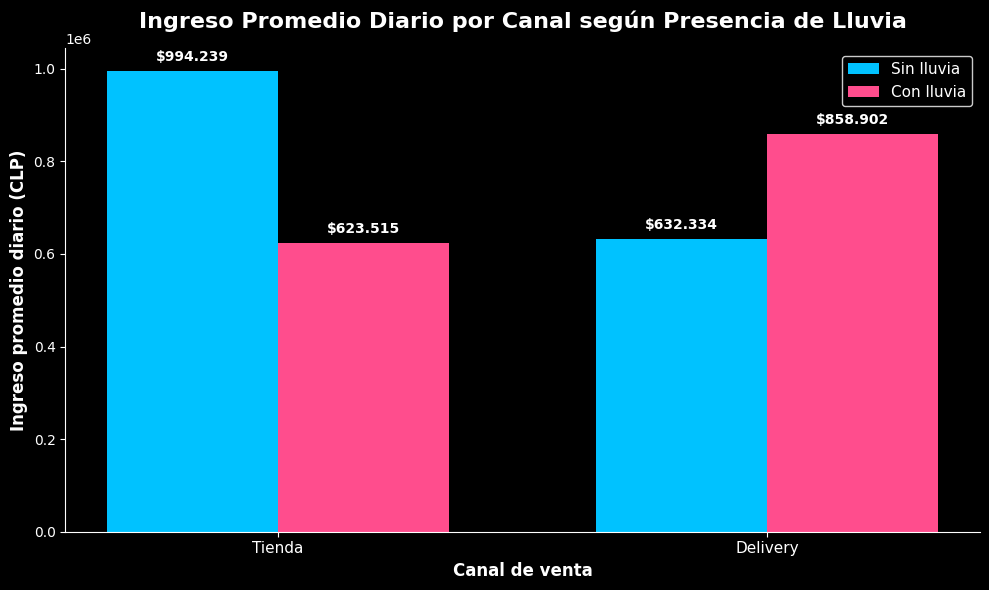

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Preparar datos para el gráfico
grafico_lluvia = promedio_lluvia_canal.pivot(
    index="canal",
    columns="lluvia",
    values="promedio_ingreso_dia"
)

# Ordenar para que salga Tienda y Delivery
grafico_lluvia = grafico_lluvia.reindex(["Tienda", "Delivery"])

# Crear figura
fig, ax = plt.subplots(figsize=(10, 6), facecolor="black")
ax.set_facecolor("black")

# Posiciones
x = np.arange(len(grafico_lluvia.index))
width = 0.35

# Barras
barras1 = ax.bar(
    x - width/2,
    grafico_lluvia["Sin lluvia"],
    width,
    label="Sin lluvia",
    color="#00C2FF"
)

barras2 = ax.bar(
    x + width/2,
    grafico_lluvia["Con lluvia"],
    width,
    label="Con lluvia",
    color="#FF4D8D"
)

# Título y ejes
ax.set_title(
    "Ingreso Promedio Diario por Canal según Presencia de Lluvia",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Canal de venta", fontsize=12, fontweight="bold", color="white")
ax.set_ylabel("Ingreso promedio diario (CLP)", fontsize=12, fontweight="bold", color="white")

# Etiquetas eje X
ax.set_xticks(x)
ax.set_xticklabels(grafico_lluvia.index, fontsize=11, color="white")

# Color de ticks eje Y
ax.tick_params(axis="y", colors="white")

# Leyenda
legend = ax.legend(facecolor="black", edgecolor="white", fontsize=11)
for text in legend.get_texts():
    text.set_color("white")

# Quitar bordes innecesarios
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

# Agregar valores sobre las barras
for barras in [barras1, barras2]:
    for barra in barras:
        altura = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width()/2,
            altura + 15000,
            f"${altura:,.0f}".replace(",", "."),
            ha="center",
            va="bottom",
            fontsize=10,
            color="white",
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

### Hallazgo

La presencia de lluvia modifica de forma importante el comportamiento por canal.

En días con precipitaciones, el ingreso promedio diario de Delivery aumenta aproximadamente un 35,8%, mientras que el ingreso promedio de Tienda disminuye cerca de un 37,3%.

También aumentan las unidades y los clientes atendidos por Delivery, lo que sugiere un desplazamiento de la demanda desde el canal presencial hacia el canal digital durante los días de lluvia.

Este resultado indica que el canal Delivery puede funcionar como una herramienta para reducir el impacto de las condiciones climáticas sobre las ventas presenciales.

## Conclusiones y recomendaciones

El análisis muestra que la estacionalidad no afecta de la misma manera a todas las categorías del negocio, sino que modifica la composición de la demanda.

### Principales hallazgos

- Los **postres fríos** presentan una mayor demanda durante los periodos de temperaturas altas y una reducción importante en condiciones de frío.
- Las **bebidas calientes** muestran el comportamiento contrario, aumentando su demanda durante los meses y días de menor temperatura.
- Los **postres calientes** presentan un comportamiento más estable, por lo que pueden funcionar como una categoría menos sensible a los cambios estacionales.
- Las precipitaciones también modifican el comportamiento de compra por canal. En días con lluvia, el ingreso promedio diario de **Delivery aumenta aproximadamente un 35,8%**, mientras que el ingreso promedio de **Tienda disminuye cerca de un 37,3%**.
- Esto indica que parte de la demanda presencial puede desplazarse hacia canales digitales cuando las condiciones climáticas dificultan la compra en tienda.

### Recomendaciones

1. **Adaptar el mix de productos según la temporada**, aumentando la visibilidad y disponibilidad de bebidas y postres calientes durante los meses fríos, y reforzando los productos fríos en periodos de mayor temperatura.

2. **Fortalecer el canal Delivery durante días de lluvia**, aumentando su visibilidad y comunicación digital, y evaluando acciones comerciales específicas para incentivar la compra desde casa.

3. **Planificar inventario y producción según patrones estacionales**, reduciendo el riesgo de sobrestock en categorías de menor demanda y asegurando disponibilidad en aquellas que aumentan según la temporada.

4. Utilizar las categorías con comportamiento más estable como apoyo para mantener ventas durante periodos de menor demanda en productos altamente estacionales.

5. Incorporar progresivamente datos reales de ventas, clima, promociones y comportamiento de clientes para validar estos patrones y mejorar la precisión de futuras decisiones comerciales.

## Limitaciones del análisis

El dataset utilizado es sintético y fue construido para representar un escenario comercial realista de un negocio de postres en Santiago de Chile.

Por esta razón, los resultados deben interpretarse como evidencia dentro del escenario simulado y no como relaciones causales demostradas sobre un negocio real.

En una aplicación real, el análisis debería validarse utilizando datos históricos de ventas, registros meteorológicos reales, información de promociones, costos y comportamiento de clientes.

## Herramientas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

**Dataset analizado:** 35.088 registros correspondientes al periodo 2024–2025.